In [2]:
#IMPORT LIBS
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
from datetime import timedelta
import cartopy.util as cutil
#import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats
import pandas as pd

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [13]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
!ls

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking
cdo    selmonth: Processed 123545136 values from 5 variables over 30681 timesteps [3.91s 2371MB]
block_clim_DAV_GHA_JJA_DJF.png
composite.svg
dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_notyrlis_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_notyrlis_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc


In [14]:
#IMPORT DATASET
ds = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc')
ds_comp = xr.open_dataset('../IVT/ERA5_IVT_northem_daily_2.5x2.5_jja_1940-2023_mod.nc')
#store variables for the composite
DAV = ds['DAV_tracked']
zg = ds['zg']/9.8
anom = ds_comp['IVT'] #converted to KJ
lat = ds['lat']
lon = ds['lon']
times = ds['time']

In [15]:
anom.shape

(7728, 37, 144)

In [16]:
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in range(n_iter):
        #print(np.arange(0,length,1))
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=False)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)

#we subtract to the anom field the annual mean in order to have only deviations from the annual mean and remove the seasonal cycle
dates = []
for time in times:
    if str(time.values)[0:4] == '1940':
        dates.append(str(time.values)[5:10])
    else:
        break
usual_year = np.zeros((len(dates),37,144))
for i,date in tqdm(enumerate(dates)):
    for t,time in enumerate(times):
        if str(time.values)[5:10] == date:
            usual_year[i,:,:] += anom[t,:,:]
usual_year = usual_year/len(dates)
usual_year_repeat = np.repeat(usual_year, 84, axis = 0)
anom = anom - usual_year_repeat

In [22]:
#compute the composites
plon,plat = -35,70 #Greenland Blocking
#plon,plat = 10,55 #European Blocking

series = DAV.loc[:,plat,plon]
list_retrograding = []
list_an_retrograding = []
list_upstream = []
list_an_upstream = []
#summer
labels_retrograding = [26, 32, 35, 39, 41, 43, 92, 96, 101, 110, 112, 157, 164, 165, 227, 237, 239, 286, 287, 293, 295, 353, 354, 365, 424, 426, 472, 480, 483, 550, 561, 564, 565, 609, 611, 614, 620, 622, 628, 683, 691, 694, 697, 700, 705, 755, 771, 820, 832, 891, 897, 903, 907, 909, 958, 967, 975, 976, 1028, 1099, 1106, 1109, 1167, 1169, 1181, 1237, 1242, 1251, 1301, 1308, 1313, 1383, 1389, 1391, 1401, 1405, 1454, 1505, 1512, 1527, 1583, 1592, 1662, 1723, 1728, 1733, 1779, 1792, 1795, 1796, 1926, 1937, 1940, 1942, 1946, 2010, 2014, 2019, 2026, 2087, 2088, 2091, 2162, 2173, 2227, 2234, 2324, 2378, 2385, 2394, 2402, 2455, 2472, 2533, 2535, 2546, 2637, 2640, 2687, 2689, 2696, 2697, 2699, 2764, 2827, 2829, 2832, 2838, 2889, 2900, 2959, 2960, 2964, 2966, 3107, 3110, 3118, 3187, 3193, 3195, 3256, 3258, 3259, 3262, 3336, 3343, 3347, 3349, 3428, 3432, 3435, 3482, 3494, 3541, 3542, 3612, 3619, 3621, 3624, 3626, 3679, 3686, 3690, 3697, 3699, 3753, 3760, 3764, 3829, 3833, 3842, 3885, 3893, 3896, 3959, 4024, 4032, 4036, 4084, 4090, 4096, 4098, 4154, 4161, 4162, 4169, 4222, 4225, 4226, 4234, 4287, 4291, 4301, 4307, 4360, 4427, 4434, 4432, 4438, 4445, 4450, 4452, 4503, 4507, 4510, 4520, 4584, 4589, 4592, 4659, 4710, 4715, 4716, 4717, 4725, 4779, 4780, 4782, 4787, 4791, 4794, 4797, 4845, 4852, 4854, 4856, 4866, 4929, 4948, 5000, 5005, 5007, 5008, 5011, 5012, 5014, 5015, 5071, 5083, 5086, 5142, 5211, 5283, 5288, 5333, 5339, 5341, 5350, 5409, 5468, 5470, 5481, 5536, 5541, 5545, 5549, 5552, 5557, 5601, 5603, 5661, 5669, 5672, 5675, 5722, 5799, 5801, 5803, 5815]
labels_upstream = [37, 107, 153, 156, 222, 231, 290, 344, 414, 486, 553, 562, 569, 571, 684, 688, 689, 757, 760, 830, 906, 908, 968, 974, 1024, 1096, 1101, 1174, 1177, 1236, 1240, 1245, 1306, 1307, 1320, 1395, 1518, 1521, 1531, 1581, 1585, 1590, 1652, 1665, 1717, 1727, 1734, 1782, 1793, 1930, 1948, 2018, 2024, 2021, 2027, 2092, 2098, 2174, 2246, 2310, 2320, 2388, 2391, 2473, 2540, 2550, 2556, 2635, 2692, 2762, 2839, 2843, 2961, 2967, 2971, 2977, 2978, 2980, 3035, 3042, 3115, 3119, 3182, 3191, 3197, 3264, 3273, 3332, 3337, 3412, 3417, 3424, 3425, 3490, 3492, 3547, 3548, 3554, 3616, 3623, 3628, 3692, 3751, 3763, 3765, 3823, 3889, 3892, 3962, 4020, 4089, 4228, 4238, 4293, 4300, 4367, 4370, 4436, 4448, 4513, 4521, 4664, 4712, 4726, 4786, 4795, 4847, 4858, 4934, 4940, 4944, 5003, 5076, 5087, 5089, 5137, 5148, 5150, 5205, 5206, 5207, 5215, 5216, 5221, 5223, 5278, 5282, 5289, 5345, 5346, 5349, 5410, 5418, 5543, 5547, 5612, 5665, 5678, 5735, 5793, 5806, 5807]
print(len(times))
for t,time in tqdm(enumerate(times)):
    if series[t] in labels_retrograding:#in list_west:
        list_retrograding.append(zg.loc[time,:,:].values)
        list_an_retrograding.append(anom.loc[time,:,:].values)
    if series[t] in labels_upstream:#in list_west:
        list_upstream.append(zg.loc[time,:,:].values)
        list_an_upstream.append(anom.loc[time,:,:].values)
sum_t_retrograding = sum(list_retrograding)
sum_an_retrograding = sum(list_an_retrograding)
zg_comp_retrograding = sum_t_retrograding/len(list_retrograding)
anom_comp_retrograding = -np.mean(anom,axis=0) + sum_an_retrograding/len(list_an_retrograding)
#t_st_anom_retrograding = abs(anom_comp_retrograding/Bootstrap(anom_retrograding,len(list_an),1000)) > 2
sum_t_upstream = sum(list_upstream)
sum_an_upstream = sum(list_an_upstream)
zg_comp_upstream = sum_t_upstream/len(list_upstream)
anom_comp_upstream = -np.mean(anom,axis=0) + sum_an_upstream/len(list_an_upstream)


7728


7728it [01:49, 70.52it/s]


NameError: name 'anom_retrograding' is not defined

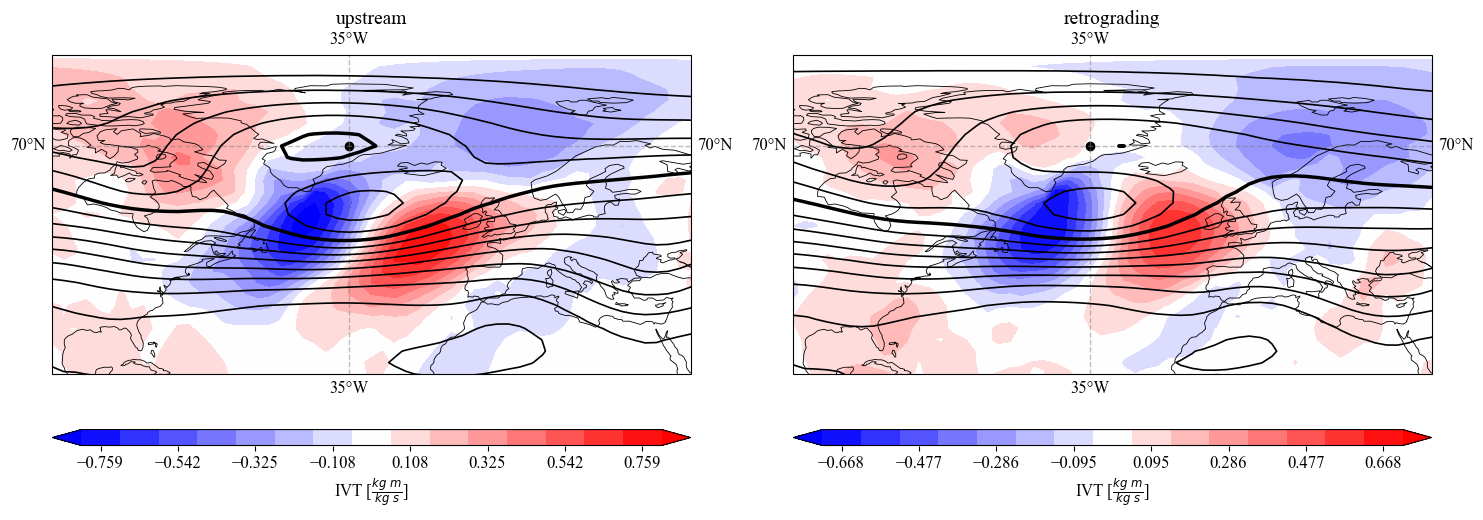

In [35]:
fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(15,6),subplot_kw={'projection': ccrs.PlateCarree()})

#FIRST PLOT
title = 'upstream'
field = ma.masked_array(zg_comp_upstream,zg_comp_upstream==0)
anom_comp = anom_comp_upstream
extent =[-100,40,20,90] #Greenland
#extent =[-180,180,20,90] #Europe
ax[0].set_extent(extent, ccrs.PlateCarree())
ax[0].coastlines(linewidth = 0.6)
ax[0].plot(plon,plat,color='black', marker='o')
gl = ax[0].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')
gl.xlocator = mticker.FixedLocator([plon])
gl.ylocator = mticker.FixedLocator([plat])
gl.xlabels_top = False
gl.ylabels_left = False
cont = ax[0].contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 1.2,
                    levels = np.arange(4600,7200,40)
                    )
cont2=ax[0].contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 2.5,
                    levels = [5600]
                    )
                    #cmap = "YlGnBu")
c_range = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/8)) + np.array(np.amax(abs(anom_comp))/16)
#c_range = np.arange(-85,86,10)
ticks = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/4)) + np.array(np.amax(abs(anom_comp))/8)
#ticks = np.arange(-85,86,10)
shadings = ax[0].contourf(lon,lat,anom_comp,
                      cmap='bwr',
                      extend = 'both', 
                      levels = c_range)
#cs_p = ax[0].contourf(lon,lat,t_st_anom,levels = 1,colors='none',hatches=['','//'])
fig.colorbar(shadings,ticks=ticks,label=r'IVT [$\frac{kg\ m}{kg\ s}$]',pad=0.1,orientation='horizontal',shrink=1,aspect=40)
ax[0].set_title(title)

# SECOND PLOT
title = 'retrograding'
field = ma.masked_array(zg_comp_retrograding,zg_comp_retrograding==0)
anom_comp = anom_comp_retrograding
extent =[-100,40,20,90] #Greenland
#extent =[-180,180,20,90] #Europe
ax[1].set_extent(extent, ccrs.PlateCarree())
ax[1].coastlines(linewidth = 0.6)
ax[1].plot(plon,plat,color='black', marker='o')
gl = ax[1].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')
gl.xlocator = mticker.FixedLocator([plon])
gl.ylocator = mticker.FixedLocator([plat])
gl.xlabels_top = False
gl.ylabels_left = False
cont = ax[1].contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 1.2,
                    levels = np.arange(4600,7200,40)
                    )
cont2=ax[1].contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 2.5,
                    levels = [5600]
                    )
                    #cmap = "YlGnBu")
c_range = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/8)) + np.array(np.amax(abs(anom_comp))/16)
#c_range = np.arange(-85,86,10)
ticks = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/4)) + np.array(np.amax(abs(anom_comp))/8)
#ticks = np.arange(-85,86,10)
shadings = ax[1].contourf(lon,lat,anom_comp,
                      cmap='bwr',
                      extend = 'both', 
                      levels = c_range)
#cs_p = ax[1].contourf(lon,lat,t_st_anom,levels = 1,colors='none',hatches=['','//'])
fig.colorbar(shadings,ticks=ticks,label=r'IVT [$\frac{kg\ m}{kg\ s}$]',pad=0.1,orientation='horizontal',shrink=1,aspect=40)
ax[1].set_title(title)

plt.tight_layout()
#plt.savefig('/Users/michelefilippucci/PLOTS/pres_exeter/winter_composite_greenland_latent_hear_west.png',dpi=300)
